<a href="https://colab.research.google.com/github/ardiresearch/riset-klasifikasi-DataBank/blob/main/P12_Praproses_dan_Pemodelan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 12 — Praproses dan Pemodelan
## Proyek Akhir Klasifikasi: k-NN dan Naive Bayes

Pembelajaran Mesin INF62325 · S1 Informatika · UIN Siber Syekh Nurjati Cirebon

### Tujuan pertemuan ini

Mengubah data mentah menjadi dua model terlatih, tanpa kebocoran data, dengan
praproses yang diletakkan di dalam `Pipeline`.

### Luaran yang dikumpulkan

| Luaran | Bentuk |
| --- | --- |
| Data latih dan data uji | tercetak ukurannya di notebook |
| Dua model terlatih beserta parameter terbaiknya | tercetak di notebook |
| Grafik pengaruh nilai k | gambar di notebook |
| `artefak_p12.joblib` | berkas di folder proyek pada Drive |

### Prasyarat

Berkas `bank-additional-full.csv` sudah ada di Google Drive Anda. Letaknya bebas;
notebook akan mencarinya sendiri.

---
## Langkah 0 — Samakan versi scikit-learn

Jalankan dua sel berikut setiap kali membuka notebook ini, sebelum sel apa pun
yang lain. Berkas model menyimpan rujukan ke kelas internal scikit-learn versi
tertentu, sehingga versi pelatihan dan versi pemuatan harus sama di seluruh
pertemuan. Angka 1.9.1 berlaku November 2026.

In [4]:
!pip install -q scikit-learn==1.9.1

**Wajib sekarang:** buka menu **Runtime**, pilih **Restart session**, lalu jalankan
ulang dari sel paling atas. Tanpa restart, Python masih memakai versi lama yang
sudah terlanjur dimuat ke memori.

In [5]:
import sklearn, pandas as pd, numpy as np, joblib

print('scikit-learn :', sklearn.__version__)
print('pandas       :', pd.__version__)

assert sklearn.__version__ == '1.9.1', (
    'Versi belum sesuai. Jalankan sel pip di atas, lalu '
    'Runtime -> Restart session, lalu ulangi dari sel pertama.'
)
print('Versi sudah sesuai.')

scikit-learn : 1.9.1
pandas       : 2.2.3
Versi sudah sesuai.


---
## Langkah 1 — Memuat data

Sel berikut memasang Drive, mencari berkas datanya, lalu membacanya. Tidak ada
`PATH` yang perlu diubah. Berkas ini memakai titik koma sebagai pemisah kolom.

In [6]:
import glob, os, time
from google.colab import drive

drive.mount('/content/drive')
FOLDER = '/content/drive/MyDrive/proyek_akhir_ml'
os.makedirs(FOLDER, exist_ok=True)

print('Mencari berkas data di Google Drive, mohon tunggu sebentar...')
temuan = sorted(glob.glob('/content/drive/MyDrive/**/bank-additional*full*.csv',
                          recursive=True))

if not temuan:
    raise FileNotFoundError(
        'Berkas bank-additional-full.csv tidak ditemukan di Google Drive Anda. '
        'Unggah dulu berkasnya, tunggu sampai tersinkron, lalu ulangi sel ini.'
    )

PATH = temuan[0]
if len(temuan) > 1:
    print(f'Ada {len(temuan)} salinan, yang dipakai salinan pertama:')
    for t in temuan:
        print('  -', t)

mentah = pd.read_csv(PATH, sep=';')
print('\nBerkas dipakai :', PATH)
print('Ukuran data    :', mentah.shape)

if mentah.shape != (41188, 21):
    print('\nPERHATIAN: ukuran seharusnya (41188, 21).')
    print('Kemungkinan berkasnya varian lain, misalnya bank.csv atau bank-full.csv.')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Mencari berkas data di Google Drive, mohon tunggu sebentar...

Berkas dipakai : /content/drive/MyDrive/Riset Praktikum/Pertemuan 12-Klasifikasi/bank-additional-full.csv
Ukuran data    : (41188, 21)


### Tiga temuan Pertemuan 11 yang dipakai di sini

1. Kelas target tidak seimbang, hanya 11,3 persen menjawab `yes`. Metrik utama
   karena itu macro-F1, bukan accuracy, dan pembagian data wajib memakai `stratify`.
2. Kolom `pdays` memakai nilai sandi 999 untuk nasabah yang belum pernah dihubungi,
   dan 999 muncul pada sekitar 96 persen baris. Kolom ini diubah menjadi penanda.
3. Kolom `duration` tidak boleh dipakai. Durasi panggilan baru diketahui setelah
   panggilan selesai, sehingga tidak tersedia saat aplikasi memprediksi.

In [7]:
TARGET = 'y'
SEED = 42
N_SUBSAMPEL = 8000

# Pembersihan berbasis aturan bidang. Boleh dikerjakan sebelum pembagian data
# karena aturannya berasal dari pengetahuan bidang, bukan dari sebaran data.
df = mentah.drop(columns=['duration']).copy()
df['pernah_dihubungi'] = np.where(df['pdays'] == 999, 'tidak', 'ya')
df = df.drop(columns=['pdays'])

print('Setelah pembersihan:', df.shape)

Setelah pembersihan: (41188, 20)


### Mengapa diambil subsampel

k-NN tidak melatih apa pun; ia menyimpan seluruh data latih lalu menghitung jarak ke
semuanya pada setiap prediksi. Pencarian parameter kita mencoba 64 kombinasi pada 5
lipatan, jadi 320 kali pelatihan. Pada 41.188 baris itu memakan lebih dari 20 menit,
sedangkan pada subsampel 8.000 baris selesai sekitar 35 detik.

Subsampel diambil berstrata dengan `random_state` tetap, sehingga proporsi kelas
terjaga dan siapa pun yang menjalankan notebook ini memperoleh baris yang sama persis.
Keputusan ini wajib ditulis di bab Metodologi laporan, lengkap dengan alasannya.

In [8]:
from sklearn.model_selection import train_test_split

df, _ = train_test_split(df, train_size=N_SUBSAMPEL,
                         stratify=df[TARGET], random_state=SEED)
df = df.reset_index(drop=True)

X = df.drop(columns=[TARGET])
y = df[TARGET]

numerik = X.select_dtypes(include='number').columns.tolist()
kategorik = X.select_dtypes(exclude='number').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print('Subsampel      :', df.shape)
print('Fitur numerik  :', len(numerik), 'kolom')
print('Fitur kategorik:', len(kategorik), 'kolom')
print('Latih          :', X_train.shape)
print('Uji            :', X_test.shape)
print('Proporsi yes di latih:', round((y_train == 'yes').mean(), 4))
print('Proporsi yes di uji  :', round((y_test == 'yes').mean(), 4))

Subsampel      : (8000, 20)
Fitur numerik  : 8 kolom
Fitur kategorik: 11 kolom
Latih          : (6400, 19)
Uji            : (1600, 19)
Proporsi yes di latih: 0.1127
Proporsi yes di uji  : 0.1125


---
## Langkah 2 — Praproses di dalam Pipeline

Satu aturan menentukan keabsahan seluruh proyek: data dibagi lebih dahulu, lalu semua
transformasi dipasang hanya pada data latih. Pelaksanaannya memakai `ColumnTransformer`
yang dibungkus di dalam `Pipeline`, sehingga imputasi dan penskalaan ikut terpasang
ulang pada setiap lipatan validasi silang.

Perhatikan parameter `pakai_skala`. k-NN bekerja atas dasar jarak sehingga menuntut
penskalaan; Naive Bayes menghitung probabilitas tiap fitur secara terpisah sehingga
tidak. Perbedaan ini disengaja dan wajib dijelaskan di laporan.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


def buat_preprocessor(pakai_skala: bool):
    """pakai_skala=True untuk model berbasis jarak seperti k-NN."""
    langkah_numerik = [('imputasi', SimpleImputer(strategy='median'))]
    if pakai_skala:
        langkah_numerik.append(('skala', StandardScaler()))

    alur_kategorik = Pipeline([
        ('imputasi', SimpleImputer(strategy='most_frequent')),
        ('encoding', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])

    return ColumnTransformer([
        ('num', Pipeline(langkah_numerik), numerik),
        ('kat', alur_kategorik, kategorik),
    ])


contoh = buat_preprocessor(True).fit_transform(X_train)
print('Jumlah kolom setelah encoding:', contoh.shape[1])

Jumlah kolom setelah encoding: 63


---
## Langkah 3 — Melatih k-NN

Tiga parameter dicari sekaligus: jumlah tetangga, pembobotan, dan metrik jarak.
64 kombinasi pada 5 lipatan berarti 320 kali pelatihan, sekitar 35 detik.

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

alur_knn = Pipeline([('prep', buat_preprocessor(pakai_skala=True)),
                     ('model', KNeighborsClassifier())])

ruang_knn = {'model__n_neighbors': list(range(1, 32, 2)),
             'model__weights': ['uniform', 'distance'],
             'model__metric': ['euclidean', 'manhattan']}

mulai = time.perf_counter()
cari_knn = GridSearchCV(alur_knn, ruang_knn, cv=cv, scoring='f1_macro', n_jobs=-1)
cari_knn.fit(X_train, y_train)
knn_terbaik = cari_knn.best_estimator_

print('Parameter terbaik :', cari_knn.best_params_)
print('Skor f1_macro CV  :', round(cari_knn.best_score_, 4))
print('Waktu pencarian   :', round(time.perf_counter() - mulai, 1), 'detik')

Parameter terbaik : {'model__metric': 'manhattan', 'model__n_neighbors': 7, 'model__weights': 'distance'}
Skor f1_macro CV  : 0.6633
Waktu pencarian   : 124.2 detik


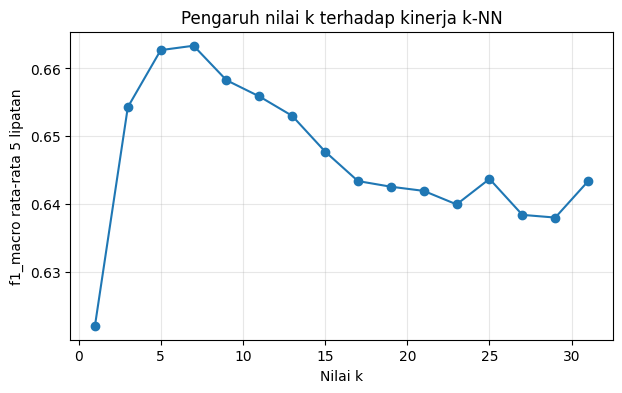

In [11]:
import matplotlib.pyplot as plt

hasil = pd.DataFrame(cari_knn.cv_results_)
baris = hasil[(hasil['param_model__weights'] == 'distance') &
              (hasil['param_model__metric'] == 'manhattan')]

plt.figure(figsize=(7, 4))
plt.plot(baris['param_model__n_neighbors'], baris['mean_test_score'], marker='o')
plt.xlabel('Nilai k')
plt.ylabel('f1_macro rata-rata 5 lipatan')
plt.title('Pengaruh nilai k terhadap kinerja k-NN')
plt.grid(alpha=0.3)
plt.show()

Bacalah grafik ini sebelum lanjut. Skor rendah pada k sangat kecil berarti model
mengikuti derau data latih; skor yang menurun pada k besar berarti batas keputusan
menjadi terlalu halus dan kelas minoritas mulai tertelan mayoritas. Posisi puncaknya
adalah k terpilih, dan Anda harus bisa menjelaskannya saat presentasi.

---
## Langkah 4 — Melatih Naive Bayes

Varian yang dipakai `GaussianNB`. Data kita campuran: delapan fitur numerik kontinu
ditambah kolom hasil one-hot yang hanya bernilai 0 dan 1. Asumsi sebaran normal jelas
tidak terpenuhi untuk kolom 0/1, dan keterbatasan itu wajib dinyatakan di laporan,
bukan disembunyikan.

`var_smoothing` menambahkan sedikit varians buatan. Parameter ini penting pada data
hasil one-hot, karena sebuah kolom bisa memiliki varians nol di dalam satu kelas dan
menyebabkan pembagian dengan nol.

In [12]:
from sklearn.naive_bayes import GaussianNB

alur_nb = Pipeline([('prep', buat_preprocessor(pakai_skala=False)),
                    ('model', GaussianNB())])

ruang_nb = {'model__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]}

cari_nb = GridSearchCV(alur_nb, ruang_nb, cv=cv, scoring='f1_macro', n_jobs=-1)
cari_nb.fit(X_train, y_train)
nb_terbaik = cari_nb.best_estimator_

print('Parameter terbaik :', cari_nb.best_params_)
print('Skor f1_macro CV  :', round(cari_nb.best_score_, 4))

Parameter terbaik : {'model__var_smoothing': 1e-06}
Skor f1_macro CV  : 0.6873


---
## Langkah 5 — Menyimpan artefak untuk Pertemuan 13

Seluruh hasil pertemuan ini disimpan dalam satu berkas di folder proyek pada Drive.
Pertemuan 13 memuat berkas itu dan melanjutkan tanpa melatih ulang apa pun.

In [13]:
artefak = {
    'X_train': X_train, 'X_test': X_test,
    'y_train': y_train, 'y_test': y_test,
    'numerik': numerik, 'kategorik': kategorik,
    'knn': knn_terbaik, 'nb': nb_terbaik,
    'param_knn': cari_knn.best_params_, 'param_nb': cari_nb.best_params_,
    'cv_knn': float(cari_knn.best_score_), 'cv_nb': float(cari_nb.best_score_),
    'kolom_encoding': int(contoh.shape[1]),
    'seed': SEED, 'versi_sklearn': sklearn.__version__,
}

jalur = os.path.join(FOLDER, 'artefak_p12.joblib')
joblib.dump(artefak, jalur)
print('Tersimpan:', jalur)
print('Ukuran   :', round(os.path.getsize(jalur) / 1024, 1), 'KB')

Tersimpan: /content/drive/MyDrive/proyek_akhir_ml/artefak_p12.joblib
Ukuran   : 4157.2 KB


---
## Daftar periksa sebelum pertemuan ditutup

- [ ] Ukuran data mentah tercetak `(41188, 21)`
- [ ] Data latih 6.400 baris dan data uji 1.600 baris
- [ ] Jumlah kolom setelah encoding tercetak 63
- [ ] Parameter k-NN terbaik dan skor validasi silangnya tercetak
- [ ] Grafik pengaruh nilai k tampil dan puncaknya dapat ditunjuk
- [ ] Parameter Naive Bayes terbaik dan skornya tercetak
- [ ] Berkas `artefak_p12.joblib` muncul di folder proyek pada Drive

### Yang perlu disiapkan untuk Pertemuan 13

Satu kalimat dugaan: model mana yang Anda perkirakan menang, dan mengapa. Dugaan itu
akan diuji pertemuan depan, dan menuliskannya lebih dulu membuat pembahasannya jauh
lebih tajam daripada sekadar membaca angka yang sudah keluar.